In [1]:
from requirements import *

# Extended Data Figure 7

In [2]:
adata_cite = sc.read_h5ad(CITE)
adata_xenv1 = sc.read_h5ad(XEN_V1)


## ED Figure 7a. CITE-seq myeloid/progenitor marker dotplot

categories: Erythroid, HSPC, Macrophage, etc.
var_group_labels: Monocytes, Myeloid Progenitor, Macrophages, etc.


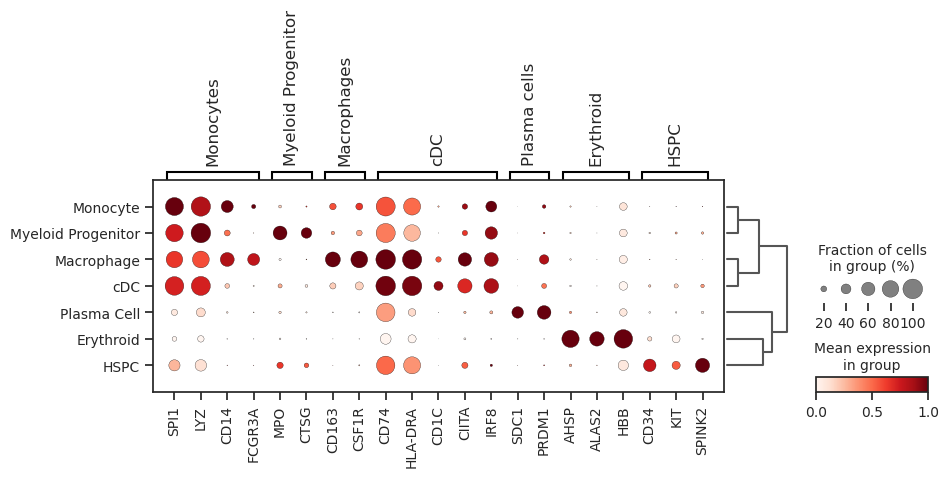

In [3]:
### Dotplot for CD45dim populations
sns.set_style("ticks")
plt.rcParams['patch.edgecolor'] = 'black'

ct_dict = {
    "Monocytes": ["SPI1", "LYZ", "CD14", "FCGR3A"],
    "Myeloid Progenitor": ["MPO", "CTSG"],
    "Macrophages": ["CD163", "CSF1R"],
    "cDC": ["CD74","HLA-DRA", "CD1C", "CIITA", "IRF8"],
    "Plasma cells": ["SDC1", "PRDM1"],
    "Erythroid": ["AHSP", "ALAS2", "HBB"],
    "HSPC": ["CD34", "KIT", "SPINK2"],
}

tmp = adata_cite[~(adata_cite.obs['ct_general'].isin(['T Cell','NK','B Cell', 'pDC']))]
tmp = tmp[tmp.obs['type'].isin(['Control','MDS', 'MDS-EB1','MDS-EB2'])]

ctlst = tmp.obs['ct_general'].unique()

gene_list = list(itertools.chain.from_iterable(list(ct_dict.values())))
ct_pos = [[i for i,j in enumerate(gene_list) if j in val] for val in ct_dict.values()]
ct_pos = [(i[0],i[0]) if len(i)==1 else (i[0],i[-1]) for i in ct_pos]


ax = sc.pl.dotplot(tmp, gene_list, groupby=['ct_general'], dendrogram=True, 
                   var_group_positions=ct_pos, mean_only_expressed = True, vmax = 1, vmin = 0,
                   expression_cutoff = 0.3,standard_scale = 'var', 
                   use_raw = False,  var_group_labels=list(ct_dict.keys()),
                   figsize=(10,2.75))


## ED Figure 7b. Xenium cell-type marker dotplots (all cell types; CITE subset)


In [4]:
from scipy import stats
topgenes = dict()
alltopgenes = set()
remove =  ['HLA-B','HLA-C','HLA-A','CXCL12','S100A9']
for ct in adata_xenv1.obs['ct_general'].unique():
    #print(ct)
    tmp = adata_xenv1[adata_xenv1.obs['ct_general'] == ct]
    tmp.X_norm = sc.pp.normalize_total(tmp, target_sum=1, inplace=False)['X']

    tmp.var['mean_expression'] = np.ravel(tmp.X_norm.mean(0))
    
    # return pd.DataFrame of 15 top-ranked genes by mean expression
    df = pd.DataFrame(tmp.var.nlargest(15, 'mean_expression')['mean_expression'])
    topgenes[ct] = [x for x in df.index if not x in remove][0:10]


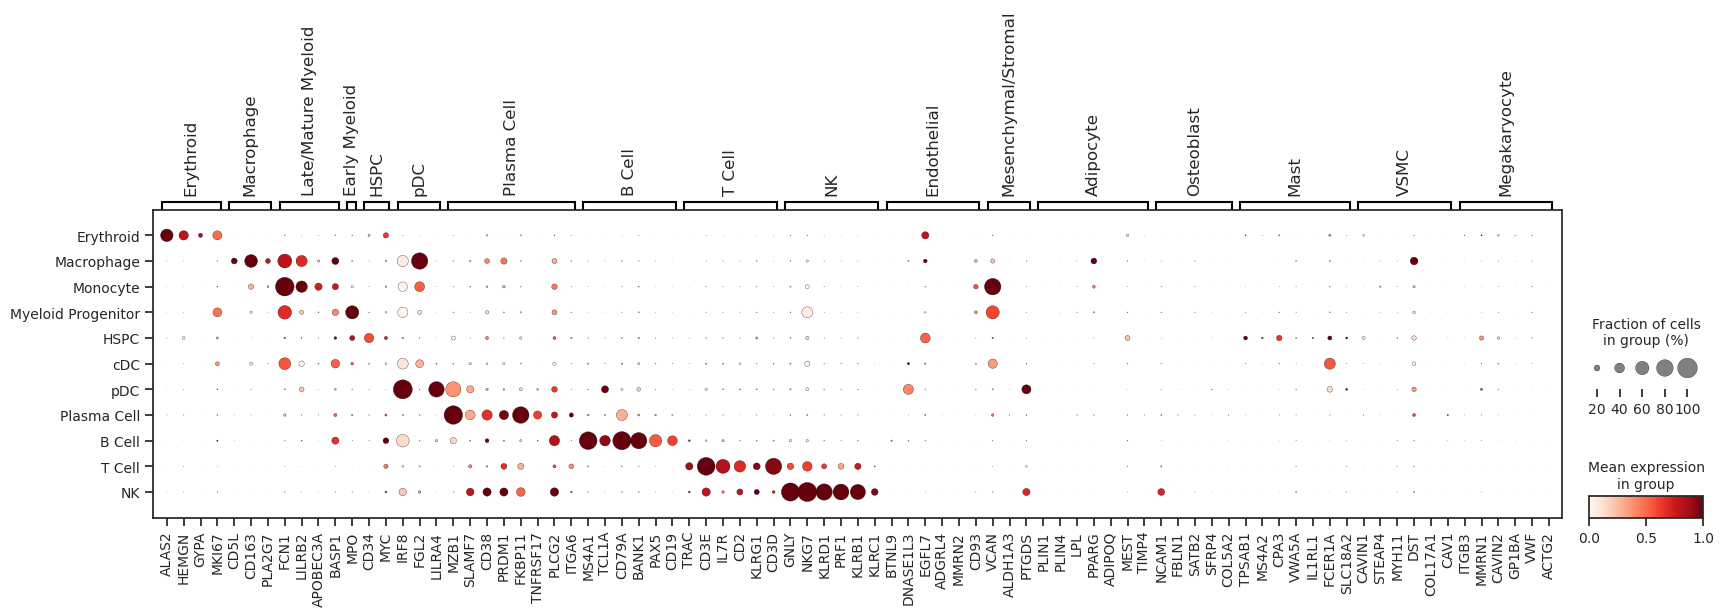

In [5]:

lst = []
for ct in topgenes:
    lst.extend(topgenes[ct][0:10])
counts = Counter(lst)
remove = [x for x in counts if counts[x] > 1] # remove top genes shared between cell types

sanitize_di = dict()
for ct in topgenes:
    currlst = [x for x in topgenes[ct] if x in adata_cite.var_names][0:10]
    sanitize_di[ct] = [x for x in currlst if not x in remove]
    
ctlst = topgenes.keys()
tmp = adata_cite[adata_cite.obs['type'].isin(['Control','MDS', 'MDS-EB1','MDS-EB2'])]
order = ['Erythroid','Macrophage','Monocyte','Myeloid Progenitor', 'HSPC','cDC','pDC','Plasma Cell','B Cell','T Cell', 'NK']
di_order = ['Erythroid','Macrophage','Late/Mature Myeloid','Early Myeloid','HSPC', 'pDC','Plasma Cell','B Cell','T Cell','NK','Endothelial','Mesenchymal/Stromal','Adipocyte','Osteoblast','Mast','VSMC','Megakaryocyte']

reordered_di = {key: sanitize_di[key] for key in di_order}

gene_list = list(itertools.chain.from_iterable(list(reordered_di.values())))
ct_pos = [[i for i,j in enumerate(gene_list) if j in val] for val in reordered_di.values()]
ct_pos = [(i[0],i[0]) if len(i)==1 else (i[0],i[-1]) for i in ct_pos]

ax = sc.pl.dotplot(tmp, gene_list, groupby=['ct_general'], dendrogram=False, 
                   mean_only_expressed = True, vmax = 1, var_group_positions=ct_pos, 
                   expression_cutoff = 1,standard_scale = 'var', categories_order = order,
                   use_raw = False, var_group_labels=list(reordered_di.keys()),
                   figsize=(20,4))


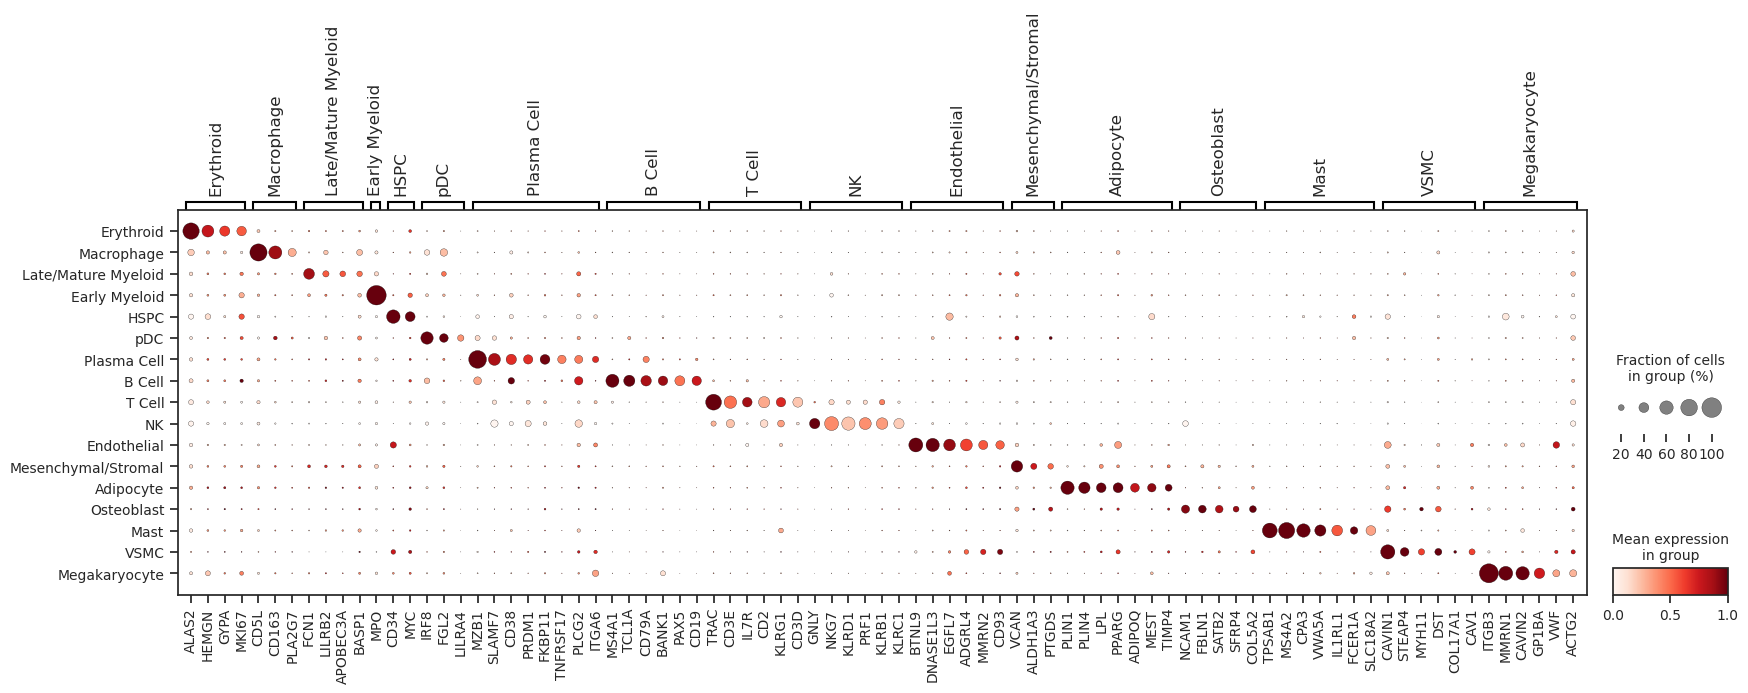

In [6]:
gene_list = list(itertools.chain.from_iterable(list(reordered_di.values())))
ct_pos = [[i for i,j in enumerate(gene_list) if j in val] for val in reordered_di.values()]
ct_pos = [(i[0],i[0]) if len(i)==1 else (i[0],i[-1]) for i in ct_pos]

ax = sc.pl.dotplot(adata_xenv1, gene_list, groupby=['ct_general'], dendrogram=False, 
                   mean_only_expressed = True, vmax = 1, var_group_positions=ct_pos, 
                   expression_cutoff = 1,standard_scale = 'var', categories_order = reordered_di.keys(),
                   use_raw = False, var_group_labels=list(reordered_di.keys()),
                   figsize=(20,5))


## ED Figure 7c. Mean VSIR / LGALS9 / S100A9 expression, Control vs MDS


In [21]:
ad_tmp = adata_cite[adata_cite.obs['ct_general'] == 'Monocyte']
ad_tmp = ad_tmp[ad_tmp.obs['type'].isin(['Control','MDS', 'MDS-EB1','MDS-EB2'])]
ad_tmp.obs.loc[ad_tmp.obs['type'].isin(['MDS-EB1','MDS-EB2']), 'type'] = 'MDS'
ad_tmp.obs['type'] = [str(x) for x in ad_tmp.obs['type']]

df = sc.get.obs_df(ad_tmp, keys=['VSIR','patient',"type"])
counts = df['patient'].value_counts()
keep = counts[counts > 10].index.tolist()
df = df[df['patient'].isin(keep)]
expr_df = pd.DataFrame(df.groupby(['patient'])['VSIR'].mean())
di = dict(zip(ad_tmp.obs['patient'], ad_tmp.obs['type']))
expr_df['type'] = [di[x] for x in expr_df.index]
expr_df


,VSIR,type
patient,,
EDTA_005,1.722379,MDS
EDTA_006,1.595232,MDS
EDTA_016_T1,1.048981,Control
HSS_78,1.448807,Control
HSS_79,1.282168,Control
HSS_91,1.281844,Control
HSS_179,1.404544,Control
HSS_214,1.615114,Control
MDS_1_T1,1.903875,MDS


In [22]:
ad_tmp = adata_cite[adata_cite.obs['ct_general'] == 'Macrophage']
ad_tmp = ad_tmp[ad_tmp.obs['type'].isin(['Control','MDS', 'MDS-EB1','MDS-EB2'])]
ad_tmp.obs.loc[ad_tmp.obs['type'].isin(['MDS-EB1','MDS-EB2']), 'type'] = 'MDS'
ad_tmp.obs['type'] = [str(x) for x in ad_tmp.obs['type']]

df = sc.get.obs_df(ad_tmp, keys=['LGALS9', 'S100A9','patient',"type"])
counts = df['patient'].value_counts()
keep = counts[counts > 10].index.tolist()
df = df[df['patient'].isin(keep)]
df1 = pd.DataFrame(df.groupby(['patient'])['LGALS9'].mean())
df2 = pd.DataFrame(df.groupby(['patient'])['S100A9'].mean())
expr_df = pd.concat([df1, df2], axis = 1)
di = dict(zip(ad_tmp.obs['patient'], ad_tmp.obs['type']))
expr_df['type'] = [di[x] for x in expr_df.index]
expr_df


,LGALS9,S100A9,type
patient,,,
EDTA_005,1.201962,0.731591,MDS
EDTA_006,0.959279,1.172175,MDS
EDTA_016_T1,NaN,NaN,Control
HSS_78,0.524515,0.818938,Control
HSS_79,0.349730,0.484541,Control
HSS_91,0.675560,0.640746,Control
HSS_179,NaN,NaN,Control
HSS_214,0.401757,0.424279,Control
MDS_1_T1,0.357010,1.039872,MDS
